# Modelo No Supervisado — Perfiles de Pozos

## Objetivo

El objetivo de este análisis es identificar grupos de pozos con comportamientos productivos similares mediante técnicas de aprendizaje no supervisado.

Se utilizarán principalmente K-Means y DBSCAN para segmentar los pozos según características productivas y operativas, buscando obtener perfiles interpretables que complementen el análisis supervisado realizado previamente.

El análisis se realizará a nivel de pozo, construyendo un dataset con una fila por `idpozo`.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.metrics import silhouette_score

## 2. Construcción del dataset a nivel pozo

Para aplicar técnicas de clustering es necesario trabajar con una única fila por pozo.

A partir del historial mensual de producción, se construirán variables resumen que representen el comportamiento productivo de cada pozo sin utilizar información futura de manera indebida.

Se considerarán variables relacionadas con:

- nivel de producción;
- variabilidad;
- tendencia reciente;
- profundidad;
- comportamiento histórico.

In [2]:
ruta = "../data/processed/pozos_maduros_sin_leakage_dic2024.csv"

df = pd.read_csv(ruta)

print("Registros:", len(df))
print("Pozos:", df["idpozo"].nunique())

df.head()

Registros: 38858
Pozos: 580


C:\Users\Milagros\AppData\Local\Temp\ipykernel_29000\2621558810.py:3: DtypeWarning: Columns (16) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(ruta)


,idempresa,anio,mes,idpozo,prod_pet,prod_gas,prod_agua,iny_agua,iny_gas,iny_co2,...,idareayacimiento,areayacimiento,cuenca,provincia,tipo_de_recurso,proyecto,clasificacion,subclasificacion,sub_tipo_recurso,fecha_data
0,ERR,2021,1,8380,26.52882,0.530576,0.338153,0.0,0.0,0.0,...,CHA,CHAÑARES HERRADOS,CUYANA,Mendoza,CONVENCIONAL,Sin Proyecto,NaN,NaN,NaN,2021-01-31
1,ACO,2021,3,8380,15.08000,0.600000,2.870000,0.0,0.0,0.0,...,CHA,CHAÑARES HERRADOS,CUYANA,Mendoza,CONVENCIONAL,Sin Proyecto,NaN,NaN,NaN,2021-03-31
2,ACO,2021,4,8380,24.29000,0.370000,0.000000,0.0,0.0,0.0,...,CHA,CHAÑARES HERRADOS,CUYANA,Mendoza,CONVENCIONAL,Sin Proyecto,NaN,NaN,NaN,2021-04-30
3,ACO,2021,5,8380,27.10000,0.420000,0.000000,0.0,0.0,0.0,...,CHA,CHAÑARES HERRADOS,CUYANA,Mendoza,CONVENCIONAL,Sin Proyecto,NaN,NaN,NaN,2021-05-31
4,ACO,2021,6,8380,25.01000,0.520000,3.460000,0.0,0.0,0.0,...,CHA,CHAÑARES HERRADOS,CUYANA,Mendoza,CONVENCIONAL,Sin Proyecto,NaN,NaN,NaN,2021-06-30


In [3]:
print(df.columns.tolist())

print("\nTipos de datos:")
print(df.dtypes)

['idempresa', 'anio', 'mes', 'idpozo', 'prod_pet', 'prod_gas', 'prod_agua', 'iny_agua', 'iny_gas', 'iny_co2', 'iny_otro', 'tef', 'vida_util', 'tipoextraccion', 'tipoestado', 'tipopozo', 'observaciones', 'fechaingreso', 'rectificado', 'habilitado', 'idusuario', 'empresa', 'sigla', 'formprod', 'profundidad', 'formacion', 'idareapermisoconcesion', 'areapermisoconcesion', 'idareayacimiento', 'areayacimiento', 'cuenca', 'provincia', 'tipo_de_recurso', 'proyecto', 'clasificacion', 'subclasificacion', 'sub_tipo_recurso', 'fecha_data']

Tipos de datos:
idempresa                  object
anio                        int64
mes                         int64
idpozo                      int64
prod_pet                  float64
prod_gas                  float64
prod_agua                 float64
iny_agua                  float64
iny_gas                   float64
iny_co2                   float64
iny_otro                  float64
tef                       float64
vida_util                 float64
tipoext

In [4]:
candidatas = [
    "prod_pet",
    "prod_gas",
    "prod_agua",
    "iny_agua",
    "iny_gas",
    "iny_co2",
    "iny_otro",
    "tef",
    "vida_util",
    "profundidad"
]

resumen = pd.DataFrame({
    "dtype": df[candidatas].dtypes,
    "nulos": df[candidatas].isna().sum(),
    "pct_nulos": (df[candidatas].isna().mean() * 100).round(2),
    "n_unicos": df[candidatas].nunique(),
    "media": df[candidatas].mean(numeric_only=True).round(2),
    "std": df[candidatas].std(numeric_only=True).round(2),
    "min": df[candidatas].min(numeric_only=True).round(2),
    "max": df[candidatas].max(numeric_only=True).round(2)
})

resumen

,dtype,nulos,pct_nulos,n_unicos,media,std,min,max
prod_pet,float64,0,0.00,24860,100.06,97.06,0.0,1245.60
prod_gas,float64,0,0.00,8493,4.72,6.46,0.0,139.31
prod_agua,float64,0,0.00,36070,3421.63,4486.61,0.0,28221.28
iny_agua,float64,0,0.00,7,0.10,8.11,0.0,1003.68
iny_gas,float64,0,0.00,1,0.00,0.00,0.0,0.00
iny_co2,float64,0,0.00,1,0.00,0.00,0.0,0.00
iny_otro,float64,0,0.00,1,0.00,0.00,0.0,0.00
tef,float64,0,0.00,3224,27.72,6.87,0.0,31.00
vida_util,float64,38834,99.94,1,0.00,0.00,0.0,0.00
profundidad,float64,0,0.00,371,2492.74,545.50,0.0,4007.00


In [5]:
print("Registros con iny_agua > 0:",
      (df["iny_agua"] > 0).sum())

print("Pozos con al menos una inyección de agua:",
      df.loc[df["iny_agua"] > 0, "idpozo"].nunique())

print("Porcentaje de pozos con inyección de agua:",
      round(
          df.loc[df["iny_agua"] > 0, "idpozo"].nunique()
          / df["idpozo"].nunique() * 100,
          2
      ),
      "%"
)

Registros con iny_agua > 0: 6
Pozos con al menos una inyección de agua: 2
Porcentaje de pozos con inyección de agua: 0.34 %


### Selección inicial de variables

Se descartaron las variables de inyección de gas, CO₂ y otros fluidos debido a que no presentan variabilidad en el conjunto analizado.

La variable `vida_util` también se excluyó por presentar más del 99% de valores faltantes.

La variable `iny_agua` fue evaluada, pero solo presenta valores positivos en 2 de los 580 pozos analizados (0,34%), por lo que no se utilizará como variable principal de clustering.

Se trabajará inicialmente con variables asociadas a producción, comportamiento operativo y características físicas del pozo.

In [6]:
dataset_pozos = (
    df.groupby("idpozo")
      .agg(
          prod_pet_media=("prod_pet", "mean"),
          prod_pet_mediana=("prod_pet", "median"),
          prod_pet_std=("prod_pet", "std"),
          prod_pet_max=("prod_pet", "max"),

          prod_gas_media=("prod_gas", "mean"),
          prod_agua_media=("prod_agua", "mean"),

          tef_media=("tef", "mean"),
          tef_std=("tef", "std"),

          profundidad=("profundidad", "median")
      )
      .reset_index()
)

print("Filas:", len(dataset_pozos))
print("Pozos únicos:", dataset_pozos["idpozo"].nunique())

dataset_pozos.head()

Filas: 580
Pozos únicos: 580


,idpozo,prod_pet_media,prod_pet_mediana,prod_pet_std,prod_pet_max,prod_gas_media,prod_agua_media,tef_media,tef_std,profundidad
0,8380,11.845057,10.40000,4.522222,27.100,0.434337,3.353137,29.864478,3.797477,3266.0
1,8392,86.447015,90.84000,38.221423,183.350,3.458209,142.949104,26.376119,8.585376,3331.0
2,8397,69.284587,74.82000,37.275102,167.510,2.782635,217.490569,26.393713,9.450449,3180.0
3,10628,203.265750,209.23700,58.176094,337.530,11.240912,47.979588,28.867353,3.316222,3710.0
4,39203,50.522360,57.54502,38.264441,103.503,0.000000,186.607071,19.552861,13.975350,2343.0


In [7]:
print(dataset_pozos.isna().sum())

idpozo              0
prod_pet_media      0
prod_pet_mediana    0
prod_pet_std        0
prod_pet_max        0
prod_gas_media      0
prod_agua_media     0
tef_media           0
tef_std             0
profundidad         0
dtype: int64


In [8]:
corr = dataset_pozos.drop(columns="idpozo").corr()

corr.round(2)

,prod_pet_media,prod_pet_mediana,prod_pet_std,prod_pet_max,prod_gas_media,prod_agua_media,tef_media,tef_std,profundidad
prod_pet_media,1.00,0.99,0.76,0.92,0.65,0.15,0.24,-0.28,0.14
prod_pet_mediana,0.99,1.00,0.74,0.89,0.65,0.17,0.22,-0.24,0.12
prod_pet_std,0.76,0.74,1.00,0.90,0.42,-0.07,-0.12,0.13,0.29
prod_pet_max,0.92,0.89,0.90,1.00,0.53,0.02,0.13,-0.16,0.27
prod_gas_media,0.65,0.65,0.42,0.53,1.00,0.53,0.23,-0.24,-0.22
prod_agua_media,0.15,0.17,-0.07,0.02,0.53,1.00,0.10,-0.14,-0.46
tef_media,0.24,0.22,-0.12,0.13,0.23,0.10,1.00,-0.90,0.00
tef_std,-0.28,-0.24,0.13,-0.16,-0.24,-0.14,-0.90,1.00,0.02
profundidad,0.14,0.12,0.29,0.27,-0.22,-0.46,0.00,0.02,1.00


In [9]:
variables_cluster = [
    "prod_pet_media",
    "prod_pet_std",
    "prod_gas_media",
    "prod_agua_media",
    "tef_media",
    "profundidad"
]

X = dataset_pozos[variables_cluster].copy()

print(X.shape)
X.head()

(580, 6)


,prod_pet_media,prod_pet_std,prod_gas_media,prod_agua_media,tef_media,profundidad
0,11.845057,4.522222,0.434337,3.353137,29.864478,3266.0
1,86.447015,38.221423,3.458209,142.949104,26.376119,3331.0
2,69.284587,37.275102,2.782635,217.490569,26.393713,3180.0
3,203.265750,58.176094,11.240912,47.979588,28.867353,3710.0
4,50.522360,38.264441,0.000000,186.607071,19.552861,2343.0


## 3. Escalado de variables

Como los algoritmos de clustering basados en distancia son sensibles a la escala de las variables, se aplicará una estandarización mediante `StandardScaler`.

Este procedimiento transforma las variables para que tengan media cercana a 0 y desvío estándar cercano a 1, evitando que aquellas con valores numéricamente más grandes dominen la formación de los clusters.

In [10]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

X_scaled = pd.DataFrame(
    X_scaled,
    columns=variables_cluster,
    index=X.index
)

print("Dimensiones:", X_scaled.shape)

X_scaled.describe().round(2)

Dimensiones: (580, 6)


,prod_pet_media,prod_pet_std,prod_gas_media,prod_agua_media,tef_media,profundidad
count,580.00,580.00,580.00,580.00,580.00,580.00
mean,-0.00,0.00,-0.00,0.00,0.00,-0.00
std,1.00,1.00,1.00,1.00,1.00,1.00
min,-1.14,-1.10,-0.96,-0.80,-5.99,-4.57
25%,-0.59,-0.63,-0.64,-0.72,-0.21,-0.76
50%,-0.24,-0.27,-0.32,-0.42,0.36,-0.17
75%,0.34,0.36,0.30,0.27,0.63,0.47
max,9.75,7.05,7.68,3.96,0.84,2.78


## 4. Selección del número de clusters

Para determinar una cantidad adecuada de clusters se evaluarán distintos valores de `k` mediante:

- método del codo, utilizando la inercia;
- índice Silhouette, que mide qué tan bien separados y cohesionados se encuentran los grupos.

Se analizarán valores de `k` entre 2 y 8.

In [11]:
inercias = []
silhouettes = []

rango_k = range(2, 9)

for k in rango_k:
    modelo = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    
    etiquetas = modelo.fit_predict(X_scaled)

    inercias.append(modelo.inertia_)
    silhouettes.append(
        silhouette_score(X_scaled, etiquetas)
    )

resultados_k = pd.DataFrame({
    "k": list(rango_k),
    "inercia": inercias,
    "silhouette": silhouettes
})

resultados_k.round(3)

,k,inercia,silhouette
0,2,2663.403,0.325
1,3,2137.078,0.327
2,4,1740.807,0.333
3,5,1449.580,0.314
4,6,1243.704,0.303
5,7,1125.484,0.283
6,8,1032.974,0.297


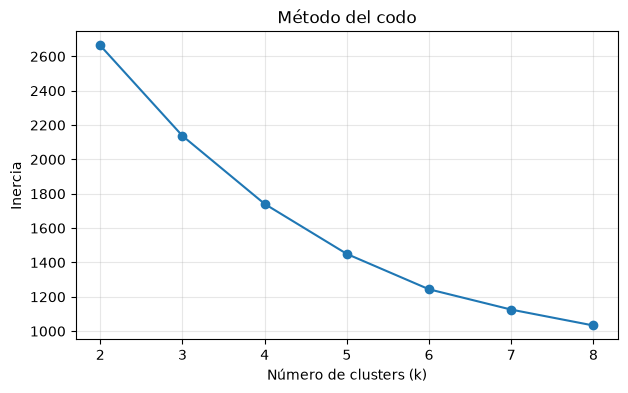

In [12]:
plt.figure(figsize=(7, 4))
plt.plot(list(rango_k), inercias, marker="o")
plt.xlabel("Número de clusters (k)")
plt.ylabel("Inercia")
plt.title("Método del codo")
plt.grid(alpha=0.3)
plt.show()

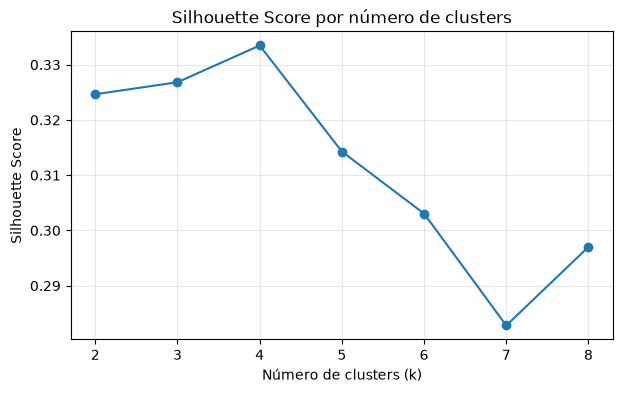

In [13]:
plt.figure(figsize=(7, 4))
plt.plot(list(rango_k), silhouettes, marker="o")
plt.xlabel("Número de clusters (k)")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Score por número de clusters")
plt.grid(alpha=0.3)
plt.show()

### Selección de k

El método del codo muestra una reducción importante de la inercia hasta aproximadamente `k = 4`, a partir de donde las mejoras comienzan a ser más graduales.

Además, el índice Silhouette alcanza su valor máximo para `k = 4` (`0.333`), lo que indica que esta cantidad de clusters presenta el mejor equilibrio entre cohesión interna y separación entre grupos entre las alternativas analizadas.

Por este motivo, se selecciona `k = 4` para el modelo K-Means final.

In [14]:
k_optimo = 4

kmeans_final = KMeans(
    n_clusters=k_optimo,
    random_state=42,
    n_init=10
)

dataset_pozos["cluster_kmeans"] = kmeans_final.fit_predict(X_scaled)

print(dataset_pozos["cluster_kmeans"].value_counts().sort_index())

cluster_kmeans
0    122
1     71
2    356
3     31
Name: count, dtype: int64


In [15]:
perfil_clusters = (
    dataset_pozos
    .groupby("cluster_kmeans")[variables_cluster]
    .mean()
    .round(2)
)

perfil_clusters

,prod_pet_media,prod_pet_std,prod_gas_media,prod_agua_media,tef_media,profundidad
cluster_kmeans,,,,,,
0,122.46,28.06,10.19,10030.41,28.66,2019.25
1,62.37,41.82,2.21,2377.03,21.29,2491.31
2,79.68,24.14,2.74,1606.61,28.59,2599.21
3,332.15,111.45,11.58,645.76,28.71,3138.48


In [16]:
medianas_clusters = (
    dataset_pozos
    .groupby("cluster_kmeans")[variables_cluster]
    .median()
    .round(2)
)

medianas_clusters

,prod_pet_media,prod_pet_std,prod_gas_media,prod_agua_media,tef_media,profundidad
cluster_kmeans,,,,,,
0,112.13,24.66,9.11,10203.60,29.26,1983.0
1,58.42,36.21,1.79,1511.61,21.98,2406.0
2,67.04,19.07,2.40,1042.24,28.92,2446.5
3,306.40,99.33,8.51,171.47,29.13,3424.0


### Perfil inicial de los clusters

El análisis de medias y medianas permite identificar diferencias claras entre los cuatro grupos obtenidos con K-Means:

- **Cluster 0:** pozos con producción de petróleo relativamente alta, elevada producción de gas y fuerte presencia de agua. Además, presentan menor profundidad promedio.
- **Cluster 1:** pozos con menor producción de petróleo, mayor variabilidad relativa y menor TEF, lo que podría asociarse a un comportamiento productivo menos estable.
- **Cluster 2:** concentra la mayor cantidad de pozos y presenta valores intermedios de producción, variabilidad y profundidad. Puede interpretarse como el perfil productivo más representativo del conjunto.
- **Cluster 3:** grupo reducido de pozos con producción de petróleo muy alta, mayor variabilidad y mayor profundidad promedio. Representa un perfil de alta productividad y características más extremas.

Estas interpretaciones son preliminares y serán complementadas con visualizaciones y con la comparación frente a DBSCAN.

<Figure size 800x500 with 0 Axes>

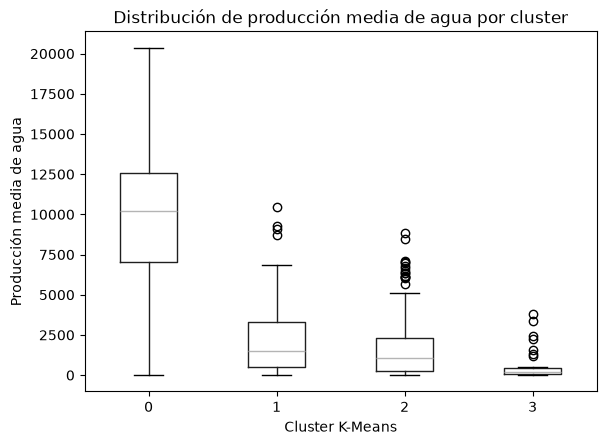

In [17]:
plt.figure(figsize=(8, 5))

dataset_pozos.boxplot(
    column="prod_agua_media",
    by="cluster_kmeans",
    grid=False
)

plt.title("Distribución de producción media de agua por cluster")
plt.suptitle("")
plt.xlabel("Cluster K-Means")
plt.ylabel("Producción media de agua")
plt.show()

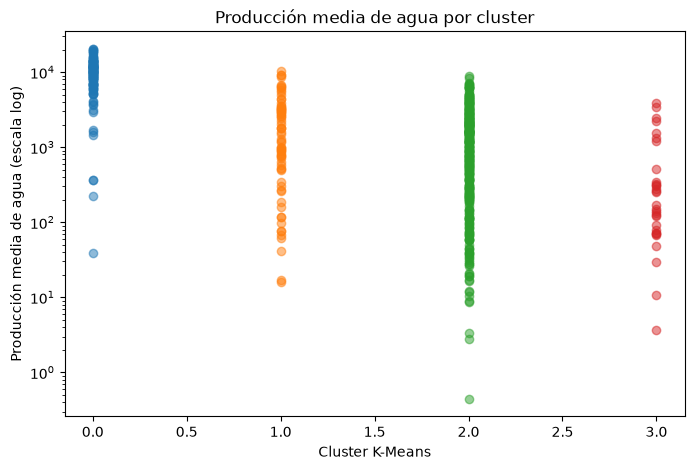

In [18]:
plt.figure(figsize=(8, 5))

for cluster in sorted(dataset_pozos["cluster_kmeans"].unique()):
    valores = dataset_pozos.loc[
        dataset_pozos["cluster_kmeans"] == cluster,
        "prod_agua_media"
    ]
    plt.scatter(
        [cluster] * len(valores),
        valores,
        alpha=0.5
    )

plt.yscale("log")
plt.xlabel("Cluster K-Means")
plt.ylabel("Producción media de agua (escala log)")
plt.title("Producción media de agua por cluster")
plt.show()

### Distribución de la producción de agua

La variable `prod_agua_media` presenta una distribución fuertemente asimétrica y varios valores extremos.

El Cluster 0 se diferencia claramente por niveles de producción de agua considerablemente superiores al resto de los grupos, mientras que los demás clusters presentan valores más bajos pero con presencia de algunos casos extremos.

Debido a esta asimetría, la interpretación de esta variable se realiza considerando tanto la media como la mediana. A pesar de los valores extremos, se mantiene dentro del análisis porque aporta información relevante para diferenciar perfiles productivos.

## 5. Clustering con DBSCAN

A diferencia de K-Means, DBSCAN no requiere definir previamente la cantidad de clusters.

Este algoritmo identifica regiones densas del espacio de características y puede clasificar como ruido a los puntos que no pertenecen a ningún grupo suficientemente denso.

Se utilizará sobre las variables estandarizadas para comparar sus resultados con los obtenidos mediante K-Means.

In [19]:
dbscan = DBSCAN(
    eps=1.2,
    min_samples=8
)

labels_dbscan = dbscan.fit_predict(X_scaled)

dataset_pozos["cluster_dbscan"] = labels_dbscan

print(
    dataset_pozos["cluster_dbscan"]
    .value_counts()
    .sort_index()
)

cluster_dbscan
-1     57
 0    523
Name: count, dtype: int64


In [20]:
resultados_dbscan = []

for eps in [0.6, 0.8, 1.0, 1.2, 1.4, 1.6, 1.8, 2.0]:
    
    modelo = DBSCAN(
        eps=eps,
        min_samples=8
    )
    
    labels = modelo.fit_predict(X_scaled)
    
    n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
    n_ruido = (labels == -1).sum()
    
    resultados_dbscan.append({
        "eps": eps,
        "n_clusters": n_clusters,
        "n_ruido": n_ruido,
        "pct_ruido": round(n_ruido / len(labels) * 100, 2)
    })

pd.DataFrame(resultados_dbscan)

,eps,n_clusters,n_ruido,pct_ruido
0,0.6,2,278,47.93
1,0.8,1,153,26.38
2,1.0,1,88,15.17
3,1.2,1,57,9.83
4,1.4,1,37,6.38
5,1.6,1,29,5.00
6,1.8,1,18,3.10
7,2.0,1,16,2.76


### Evaluación de parámetros de DBSCAN

Se probaron distintos valores de `eps` manteniendo `min_samples = 8`.

Los resultados muestran que DBSCAN tiende a identificar una única región densa principal y clasifica como ruido a los pozos más alejados de dicha región.

Con valores bajos de `eps`, como `0.6`, se obtienen dos clusters, pero casi la mitad de los pozos queda clasificada como ruido, lo que limita su utilidad para segmentar el conjunto.

A partir de `eps = 0.8`, el algoritmo identifica un solo cluster principal, reduciendo progresivamente la cantidad de ruido a medida que aumenta `eps`.

Se toma como configuración de referencia `eps = 1.2` y `min_samples = 8`, que clasifica 57 pozos como ruido (9,83%) y 523 pozos dentro de la región principal.

Estos resultados sugieren que DBSCAN es más útil en este caso para detectar pozos atípicos que para construir una segmentación completa del conjunto.S

In [21]:
pozos_ruido = dataset_pozos[
    dataset_pozos["cluster_dbscan"] == -1
].copy()

print("Cantidad de pozos considerados ruido:", len(pozos_ruido))

pozos_ruido[variables_cluster].describe().round(2)

Cantidad de pozos considerados ruido: 57


,prod_pet_media,prod_pet_std,prod_gas_media,prod_agua_media,tef_media,profundidad
count,57.00,57.00,57.00,57.00,57.00,57.00
mean,209.95,69.49,9.57,3736.54,25.30,2393.04
std,199.86,58.37,9.60,5682.54,5.70,862.35
min,5.25,4.62,0.01,0.44,10.30,0.00
25%,48.31,23.44,2.67,253.59,19.82,1985.00
50%,152.74,54.04,6.48,1343.52,28.63,2359.00
75%,317.48,100.78,11.32,3754.10,29.73,3285.00
max,950.95,234.64,42.42,20360.21,30.14,3657.00


In [22]:
comparacion_ruido = (
    dataset_pozos
    .assign(
        grupo_dbscan=np.where(
            dataset_pozos["cluster_dbscan"] == -1,
            "Ruido",
            "Cluster principal"
        )
    )
    .groupby("grupo_dbscan")[variables_cluster]
    .mean()
    .round(2)
)

comparacion_ruido

,prod_pet_media,prod_pet_std,prod_gas_media,prod_agua_media,tef_media,profundidad
grupo_dbscan,,,,,,
Cluster principal,88.08,27.68,4.19,3387.13,27.98,2503.71
Ruido,209.95,69.49,9.57,3736.54,25.30,2393.04


### Caracterización de los pozos identificados como ruido

Los 57 pozos clasificados como ruido por DBSCAN presentan diferencias importantes respecto del grupo principal.

En promedio, estos pozos muestran:

- mayor producción media de petróleo;
- mayor variabilidad en la producción;
- mayor producción media de gas;
- una ligera reducción del TEF medio;
- niveles de profundidad similares al resto del conjunto.

La diferencia más destacada se observa en la producción de petróleo: los pozos considerados ruido alcanzan una media de aproximadamente 210, frente a 88 en el grupo principal.

Estos resultados sugieren que DBSCAN está identificando principalmente pozos con comportamientos productivos más extremos o menos representativos del patrón general.

## 6. Visualización bidimensional de los clusters

Para facilitar la interpretación gráfica de los resultados, se aplica una reducción de dimensionalidad mediante SVD.

Esta técnica permite representar las seis variables utilizadas en el clustering en dos dimensiones, conservando parte de la estructura original de los datos.

La reducción se utiliza únicamente con fines de visualización y no reemplaza las variables originales empleadas para entrenar los modelos.

In [23]:
from sklearn.decomposition import TruncatedSVD

svd = TruncatedSVD(
    n_components=2,
    random_state=42
)

X_svd = svd.fit_transform(X_scaled)

dataset_pozos["svd_1"] = X_svd[:, 0]
dataset_pozos["svd_2"] = X_svd[:, 1]

print(
    "Varianza explicada acumulada:",
    round(svd.explained_variance_ratio_.sum(), 3)
)

Varianza explicada acumulada: 0.682


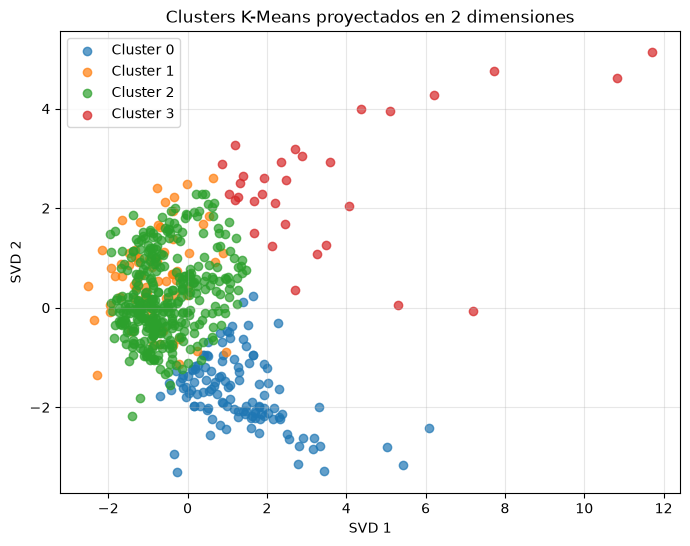

In [24]:
plt.figure(figsize=(8, 6))

for cluster in sorted(dataset_pozos["cluster_kmeans"].unique()):
    datos = dataset_pozos[
        dataset_pozos["cluster_kmeans"] == cluster
    ]
    
    plt.scatter(
        datos["svd_1"],
        datos["svd_2"],
        label=f"Cluster {cluster}",
        alpha=0.7
    )

plt.xlabel("SVD 1")
plt.ylabel("SVD 2")
plt.title("Clusters K-Means proyectados en 2 dimensiones")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### Visualización de los clusters K-Means

La proyección mediante SVD permite observar parcialmente la estructura de los grupos encontrados por K-Means.

El Cluster 3 presenta la mayor separación visual respecto del resto, lo que es consistente con su perfil de pozos de alta producción, mayor variabilidad y mayor profundidad.

El Cluster 0 también muestra una diferenciación importante, principalmente asociada a los elevados niveles de producción de agua.

Los Clusters 1 y 2 presentan mayor superposición en la representación bidimensional. Esto es esperable, ya que la proyección en dos dimensiones conserva aproximadamente el 68,2% de la variabilidad total y, por lo tanto, no representa toda la información utilizada originalmente por el modelo.

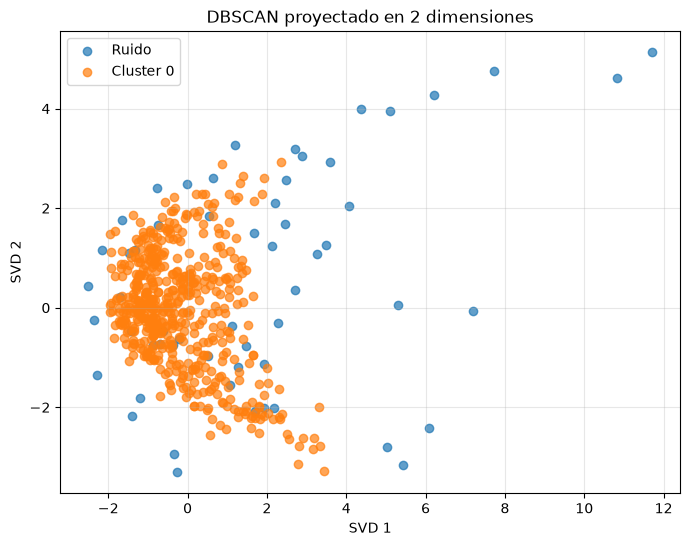

In [25]:
plt.figure(figsize=(8, 6))

for cluster in sorted(dataset_pozos["cluster_dbscan"].unique()):
    datos = dataset_pozos[
        dataset_pozos["cluster_dbscan"] == cluster
    ]

    etiqueta = "Ruido" if cluster == -1 else f"Cluster {cluster}"

    plt.scatter(
        datos["svd_1"],
        datos["svd_2"],
        label=etiqueta,
        alpha=0.7
    )

plt.xlabel("SVD 1")
plt.ylabel("SVD 2")
plt.title("DBSCAN proyectado en 2 dimensiones")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### Visualización de DBSCAN

La proyección bidimensional muestra que DBSCAN concentra la mayor parte de los pozos en un único cluster principal.

Los puntos clasificados como ruido se ubican principalmente en regiones más alejadas de la nube central, lo que respalda su interpretación como pozos con comportamientos menos representativos o más extremos.

A diferencia de K-Means, DBSCAN no genera una segmentación clara en múltiples grupos para este conjunto de datos. Sin embargo, resulta útil como herramienta complementaria para identificar observaciones atípicas.

## 7. Comparación entre K-Means y DBSCAN

Los dos algoritmos muestran comportamientos diferentes frente a la estructura de los datos.

**K-Means** permitió obtener cuatro grupos con perfiles productivos diferenciados y relativamente interpretables. Los clusters presentan diferencias en producción de petróleo, producción de agua, variabilidad, TEF y profundidad.

**DBSCAN**, en cambio, identificó principalmente una gran región densa y clasificó 57 pozos como ruido. Por lo tanto, su principal aporte en este caso fue la detección de observaciones atípicas más que la construcción de múltiples perfiles.

Para el objetivo del proyecto, K-Means resulta más adecuado como método principal de segmentación, mientras que DBSCAN funciona como herramienta complementaria para detectar pozos con comportamientos extremos.

In [26]:
nombres_clusters = {
    0: "Alta producción de agua",
    1: "Bajo desempeño / mayor inestabilidad",
    2: "Perfil productivo típico",
    3: "Alta productividad"
}

dataset_pozos["perfil_cluster"] = (
    dataset_pozos["cluster_kmeans"]
    .map(nombres_clusters)
)

dataset_pozos[
    ["idpozo", "cluster_kmeans", "perfil_cluster"]
].head(10)

,idpozo,cluster_kmeans,perfil_cluster
0,8380,2,Perfil productivo típico
1,8392,2,Perfil productivo típico
2,8397,2,Perfil productivo típico
3,10628,3,Alta productividad
4,39203,1,Bajo desempeño / mayor inestabilidad
5,39215,2,Perfil productivo típico
6,39223,1,Bajo desempeño / mayor inestabilidad
7,39225,1,Bajo desempeño / mayor inestabilidad
8,39228,1,Bajo desempeño / mayor inestabilidad
9,39237,3,Alta productividad


In [27]:
resumen_final_clusters = (
    dataset_pozos
    .groupby(["cluster_kmeans", "perfil_cluster"])
    .agg(
        cantidad_pozos=("idpozo", "count"),
        prod_pet_media=("prod_pet_media", "mean"),
        prod_pet_std=("prod_pet_std", "mean"),
        prod_gas_media=("prod_gas_media", "mean"),
        prod_agua_media=("prod_agua_media", "mean"),
        tef_media=("tef_media", "mean"),
        profundidad=("profundidad", "mean")
    )
    .round(2)
)

resumen_final_clusters

,,cantidad_pozos,prod_pet_media,prod_pet_std,prod_gas_media,prod_agua_media,tef_media,profundidad
cluster_kmeans,perfil_cluster,,,,,,,
0,Alta producción de agua,122,122.46,28.06,10.19,10030.41,28.66,2019.25
1,Bajo desempeño / mayor inestabilidad,71,62.37,41.82,2.21,2377.03,21.29,2491.31
2,Perfil productivo típico,356,79.68,24.14,2.74,1606.61,28.59,2599.21
3,Alta productividad,31,332.15,111.45,11.58,645.76,28.71,3138.48


## 8. Perfil final de los clusters

A partir de las características promedio de cada grupo, se asignaron nombres descriptivos a los clusters obtenidos mediante K-Means:

- **Cluster 0 — Alta producción de agua:** pozos con elevada producción de agua, producción de petróleo relativamente alta y menor profundidad promedio.
- **Cluster 1 — Bajo desempeño / mayor inestabilidad:** pozos con menor producción de petróleo, mayor variabilidad relativa y menor TEF.
- **Cluster 2 — Perfil productivo típico:** concentra la mayor cantidad de pozos y presenta valores intermedios y relativamente estables.
- **Cluster 3 — Alta productividad:** pozos con los mayores niveles de producción de petróleo, mayor variabilidad y mayor profundidad promedio.

Los nombres asignados son interpretativos y buscan facilitar la comunicación de los resultados del clustering.

In [28]:
ruta_salida = "../data/processed/dataset_clustering_pozos.csv"

dataset_pozos.to_csv(
    ruta_salida,
    index=False
)

print("Archivo guardado en:", ruta_salida)
print("Filas:", len(dataset_pozos))
print("Pozos únicos:", dataset_pozos["idpozo"].nunique())

Archivo guardado en: ../data/processed/dataset_clustering_pozos.csv
Filas: 580
Pozos únicos: 580


In [29]:
pd.read_csv(ruta_salida).head()

,idpozo,prod_pet_media,prod_pet_mediana,prod_pet_std,prod_pet_max,prod_gas_media,prod_agua_media,tef_media,tef_std,profundidad,cluster_kmeans,cluster_dbscan,svd_1,svd_2,perfil_cluster
0,8380,11.845057,10.40000,4.522222,27.100,0.434337,3.353137,29.864478,3.797477,3266.0,2,0,-1.667475,0.790030,Perfil productivo típico
1,8392,86.447015,90.84000,38.221423,183.350,3.458209,142.949104,26.376119,8.585376,3331.0,2,0,-0.475737,1.576594,Perfil productivo típico
2,8397,69.284587,74.82000,37.275102,167.510,2.782635,217.490569,26.393713,9.450449,3180.0,2,0,-0.671800,1.366422,Perfil productivo típico
3,10628,203.265750,209.23700,58.176094,337.530,11.240912,47.979588,28.867353,3.316222,3710.0,3,0,1.663455,2.141137,Alta productividad
4,39203,50.522360,57.54502,38.264441,103.503,0.000000,186.607071,19.552861,13.975350,2343.0,1,0,-1.483520,0.849396,Bajo desempeño / mayor inestabilidad


## AED orientado al clustering

Antes de aplicar los algoritmos de clustering se realizó un análisis exploratorio específico sobre las variables seleccionadas.

El objetivo fue evaluar:

- distribución de las variables;
- presencia de valores extremos;
- diferencias de escala;
- correlación entre variables;
- posibles redundancias.

Este análisis permitió descartar variables sin variabilidad, variables con una cantidad excesiva de valores faltantes y variables altamente redundantes.

También se detectaron distribuciones asimétricas y presencia de outliers, especialmente en variables productivas como la producción de agua. Estas características fueron consideradas durante la interpretación de los clusters y en la comparación entre K-Means y DBSCAN.

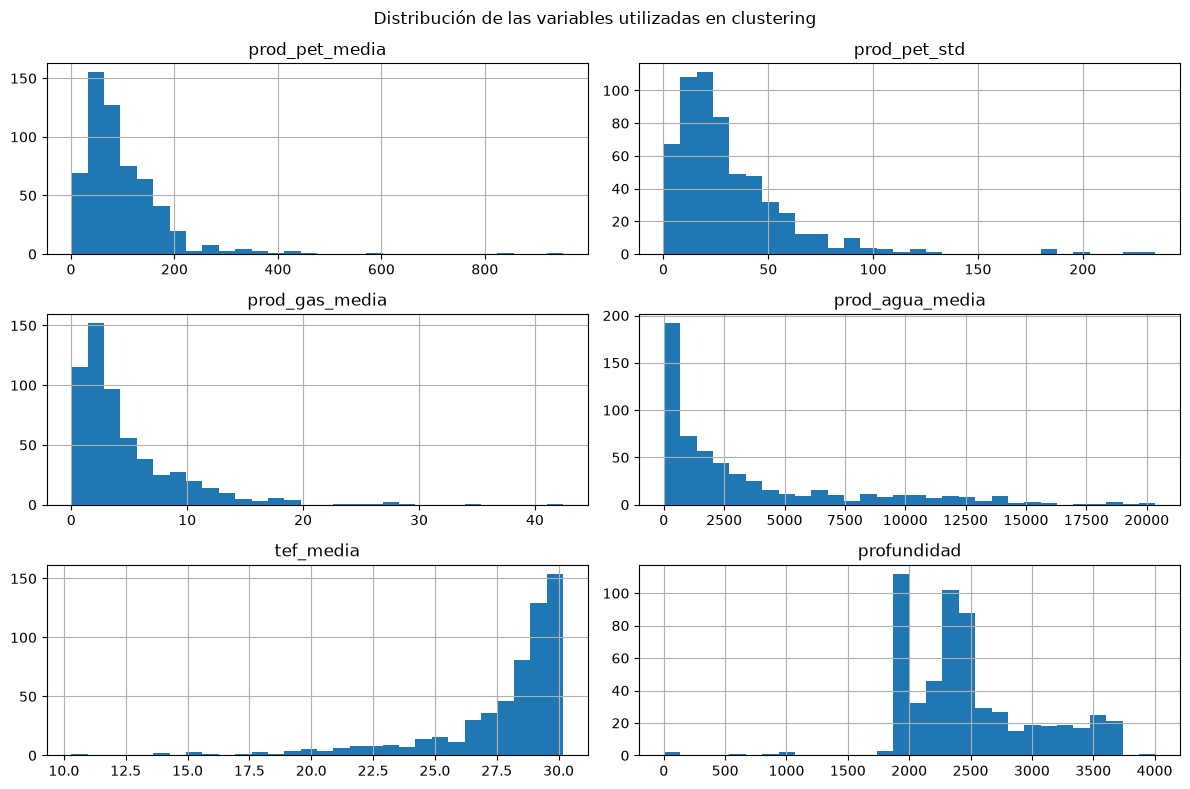

In [30]:
X.hist(
    figsize=(12, 8),
    bins=30
)

plt.suptitle("Distribución de las variables utilizadas en clustering")
plt.tight_layout()
plt.show()

## Mejora del modelo de clustering

El análisis exploratorio mostró que varias variables productivas presentan distribuciones fuertemente asimétricas y valores extremos.

Para reducir la influencia de estos valores y evaluar si se obtiene una estructura de clusters más definida, se aplicará una transformación logarítmica mediante `log1p` sobre las variables productivas positivas.

Luego se volverán a estandarizar los datos y se evaluará nuevamente K-Means utilizando el índice Silhouette.

In [31]:
X_mejorado = X.copy()

variables_log = [
    "prod_pet_media",
    "prod_pet_std",
    "prod_gas_media",
    "prod_agua_media"
]

for col in variables_log:
    X_mejorado[col] = np.log1p(X_mejorado[col])

scaler_mejorado = StandardScaler()

X_mejorado_scaled = scaler_mejorado.fit_transform(X_mejorado)

X_mejorado_scaled = pd.DataFrame(
    X_mejorado_scaled,
    columns=variables_cluster,
    index=X_mejorado.index
)

X_mejorado_scaled.describe().round(2)

,prod_pet_media,prod_pet_std,prod_gas_media,prod_agua_media,tef_media,profundidad
count,580.00,580.00,580.00,580.00,580.00,580.00
mean,-0.00,0.00,-0.00,-0.00,0.00,-0.00
std,1.00,1.00,1.00,1.00,1.00,1.00
min,-4.76,-3.64,-2.07,-3.70,-5.99,-4.57
25%,-0.52,-0.59,-0.73,-0.65,-0.21,-0.76
50%,0.07,0.05,-0.07,0.18,0.36,-0.17
75%,0.67,0.71,0.70,0.75,0.63,0.47
max,3.13,2.76,3.22,1.58,0.84,2.78


In [32]:
inercias_mejorado = []
silhouettes_mejorado = []

for k in rango_k:
    modelo = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    
    etiquetas = modelo.fit_predict(X_mejorado_scaled)

    inercias_mejorado.append(modelo.inertia_)
    silhouettes_mejorado.append(
        silhouette_score(X_mejorado_scaled, etiquetas)
    )

resultados_mejorado = pd.DataFrame({
    "k": list(rango_k),
    "inercia": inercias_mejorado,
    "silhouette": silhouettes_mejorado
})

resultados_mejorado.round(3)

,k,inercia,silhouette
0,2,2603.756,0.237
1,3,2090.256,0.264
2,4,1719.783,0.288
3,5,1496.883,0.256
4,6,1341.680,0.250
5,7,1201.620,0.261
6,8,1132.344,0.235


### Evaluación de la mejora propuesta

Se evaluó una transformación logarítmica (`log1p`) sobre las variables productivas más asimétricas, con el objetivo de reducir la influencia de valores extremos y mejorar la estructura del clustering.

Luego de volver a estandarizar las variables y entrenar K-Means para valores de `k` entre 2 y 8, el mejor índice Silhouette obtenido fue de aproximadamente `0.288` para `k = 4`.

Este resultado es inferior al alcanzado por el modelo original, cuyo mejor Silhouette fue de aproximadamente `0.333` también para `k = 4`.

Por lo tanto, aunque la transformación logarítmica mejora la simetría de las distribuciones, no mejora la separación entre clusters en este caso. Se decide conservar como modelo principal la versión original con variables estandarizadas sin transformación logarítmica.

Esta decisión se toma utilizando el índice Silhouette como criterio cuantitativo, complementado con la interpretabilidad de los perfiles obtenidos.

## 9. Conclusiones

El análisis no supervisado permitió identificar distintos perfiles productivos dentro del conjunto de 580 pozos maduros de la Cuenca Cuyana.

Mediante K-Means se seleccionó una solución de cuatro clusters, apoyada por el método del codo y el índice Silhouette. Los grupos obtenidos presentan diferencias interpretables en términos de producción de petróleo, variabilidad, producción de agua, TEF y profundidad.

Los perfiles identificados fueron:

- **Alta producción de agua:** pozos con elevada producción de agua y producción de petróleo relativamente alta.
- **Bajo desempeño / mayor inestabilidad:** pozos con menor producción de petróleo, mayor variabilidad relativa y menor TEF.
- **Perfil productivo típico:** grupo mayoritario, con valores intermedios y comportamiento relativamente estable.
- **Alta productividad:** grupo reducido de pozos con los mayores niveles de producción de petróleo, mayor variabilidad y mayor profundidad.

DBSCAN mostró un comportamiento diferente. En lugar de separar el conjunto en varios grupos, identificó una gran región principal y clasificó 57 pozos como ruido. Estos pozos presentaron, en promedio, mayor producción y variabilidad, por lo que DBSCAN resultó especialmente útil para detectar comportamientos atípicos.

Como parte del proceso de mejora, se evaluó una transformación logarítmica sobre las variables productivas más asimétricas. Sin embargo, el mejor índice Silhouette disminuyó de aproximadamente `0.333` a `0.288`, por lo que se decidió conservar la versión original de K-Means con las variables estandarizadas.

En consecuencia, K-Means se considera el método más adecuado para la segmentación principal de los pozos, mientras que DBSCAN aporta una visión complementaria para la detección de casos extremos.

La reducción de dimensionalidad mediante SVD permitió representar visualmente los resultados conservando aproximadamente el 68,2% de la variabilidad total en dos componentes.

En conjunto, el análisis permitió complementar el modelo supervisado con una segmentación descriptiva de los pozos y tomar decisiones metodológicas basadas en criterios cuantitativos e interpretabilidad.

# Complemento — Redes Neuronales

Como complemento al análisis realizado, se implementará una red neuronal multicapa para el problema de predicción de producción de petróleo.

El objetivo es evaluar si un modelo neuronal simple puede capturar relaciones no lineales entre las variables productivas y mejorar o complementar los resultados obtenidos previamente con modelos tradicionales.

Para evitar leakage y mantener una comparación justa, se utilizará el mismo esquema temporal y las mismas variables empleadas en el modelo supervisado.

In [33]:
split_h1 = pd.read_csv(
    "../data/processed/splits/split_h1.csv"
)

print("Filas:", len(split_h1))
print("Columnas:")
print(split_h1.columns.tolist())

split_h1.head()

Filas: 30724
Columnas:
['idpozo', 'fecha_data', 'split']


,idpozo,fecha_data,split
0,8380,2021-09-30,train
1,8380,2021-10-31,train
2,8380,2021-11-30,train
3,8380,2021-12-31,train
4,8380,2022-01-31,train


In [34]:
# Preparación temporal
df_nn = df.copy()

df_nn["fecha_data"] = pd.to_datetime(df_nn["fecha_data"])
df_nn = df_nn.sort_values(["idpozo", "fecha_data"]).reset_index(drop=True)

df_nn["periodo"] = df_nn["fecha_data"].dt.to_period("M")

# Lags mensuales seguros
for lag in [1, 2, 3, 6]:
    valor_lag = df_nn.groupby("idpozo")["prod_pet"].shift(lag)
    periodo_lag = df_nn.groupby("idpozo")["periodo"].shift(lag)

    esperado = df_nn["periodo"] - lag

    df_nn[f"prod_pet_lag{lag}"] = valor_lag.where(
        periodo_lag == esperado
    )

# Target H1 seguro
df_nn["target_1m"] = (
    df_nn.groupby("idpozo")["prod_pet"].shift(-1)
)

periodo_target = (
    df_nn.groupby("idpozo")["periodo"].shift(-1)
)

df_nn["target_1m"] = df_nn["target_1m"].where(
    periodo_target == df_nn["periodo"] + 1
)

print(df_nn[
    [
        "idpozo",
        "fecha_data",
        "prod_pet",
        "prod_pet_lag1",
        "prod_pet_lag2",
        "prod_pet_lag3",
        "prod_pet_lag6",
        "target_1m"
    ]
].head(10))

   idpozo fecha_data  prod_pet  prod_pet_lag1  prod_pet_lag2  prod_pet_lag3  \
0    8380 2021-01-31  26.52882            NaN            NaN            NaN   
1    8380 2021-03-31  15.08000            NaN            NaN            NaN   
2    8380 2021-04-30  24.29000          15.08            NaN            NaN   
3    8380 2021-05-31  27.10000          24.29          15.08            NaN   
4    8380 2021-06-30  25.01000          27.10          24.29          15.08   
5    8380 2021-07-31  21.16000          25.01          27.10          24.29   
6    8380 2021-08-31  11.16000          21.16          25.01          27.10   
7    8380 2021-09-30  10.30000          11.16          21.16          25.01   
8    8380 2021-10-31  26.54000          10.30          11.16          21.16   
9    8380 2021-11-30  12.03000          26.54          10.30          11.16   

   prod_pet_lag6  target_1m  
0            NaN        NaN  
1            NaN      24.29  
2            NaN      27.10  
3         

In [35]:
def rolling_seguro(grupo, ventana, estadistica):
    valores = grupo["prod_pet"].rolling(
        window=ventana,
        min_periods=ventana
    )

    if estadistica == "mean":
        resultado = valores.mean()
    elif estadistica == "std":
        resultado = valores.std()

    periodo_inicio = grupo["periodo"].shift(ventana - 1)
    periodo_esperado = grupo["periodo"] - (ventana - 1)

    return resultado.where(
        periodo_inicio == periodo_esperado
    )


for ventana in [3, 6]:

    df_nn[f"prod_pet_roll{ventana}_mean"] = (
        df_nn
        .groupby("idpozo", group_keys=False)
        .apply(
            lambda g: rolling_seguro(
                g,
                ventana,
                "mean"
            )
        )
        .reset_index(level=0, drop=True)
    )

    df_nn[f"prod_pet_roll{ventana}_std"] = (
        df_nn
        .groupby("idpozo", group_keys=False)
        .apply(
            lambda g: rolling_seguro(
                g,
                ventana,
                "std"
            )
        )
        .reset_index(level=0, drop=True)
    )

C:\Users\Milagros\AppData\Local\Temp\ipykernel_29000\3523932284.py:25: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(
C:\Users\Milagros\AppData\Local\Temp\ipykernel_29000\3523932284.py:38: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(
C:\Users\Milagros\AppData\Local\Temp\ipykernel_29000\3523932284.py:25: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated

In [36]:
columnas_nn = [
    "prod_pet",
    "prod_pet_lag1",
    "prod_pet_lag2",
    "prod_pet_lag3",
    "prod_pet_lag6",
    "prod_pet_roll3_mean",
    "prod_pet_roll3_std",
    "prod_pet_roll6_mean",
    "prod_pet_roll6_std",
    "profundidad",
    "target_1m"
]

print(df_nn[columnas_nn].isna().sum())

prod_pet                  0
prod_pet_lag1           586
prod_pet_lag2          1166
prod_pet_lag3          1746
prod_pet_lag6          3486
prod_pet_roll3_mean    1166
prod_pet_roll3_std     1166
prod_pet_roll6_mean    2906
prod_pet_roll6_std     2906
profundidad               0
target_1m               586
dtype: int64


In [37]:
split_h1["fecha_data"] = pd.to_datetime(split_h1["fecha_data"])

df_nn_split = df_nn.merge(
    split_h1,
    on=["idpozo", "fecha_data"],
    how="inner"
)

features_nn = [
    "prod_pet",
    "prod_pet_lag1",
    "prod_pet_lag2",
    "prod_pet_lag3",
    "prod_pet_lag6",
    "prod_pet_roll3_mean",
    "prod_pet_roll3_std",
    "prod_pet_roll6_mean",
    "prod_pet_roll6_std",
    "profundidad"
]

df_nn_modelo = df_nn_split.dropna(
    subset=features_nn + ["target_1m"]
).copy()

print(df_nn_modelo["split"].value_counts())
print("\nFilas totales:", len(df_nn_modelo))
print("Pozos únicos:", df_nn_modelo["idpozo"].nunique())

split
train    23764
test      6960
Name: count, dtype: int64

Filas totales: 30724
Pozos únicos: 580


In [38]:
from sklearn.preprocessing import StandardScaler

train_nn = df_nn_modelo[df_nn_modelo["split"] == "train"].copy()
test_nn = df_nn_modelo[df_nn_modelo["split"] == "test"].copy()

X_train_nn = train_nn[features_nn]
y_train_nn = train_nn["target_1m"]

X_test_nn = test_nn[features_nn]
y_test_nn = test_nn["target_1m"]

scaler_nn = StandardScaler()

X_train_nn_scaled = scaler_nn.fit_transform(X_train_nn)
X_test_nn_scaled = scaler_nn.transform(X_test_nn)

print("Train:", X_train_nn_scaled.shape)
print("Test:", X_test_nn_scaled.shape)

Train: (23764, 10)
Test: (6960, 10)


In [39]:
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

mlp = MLPRegressor(
    hidden_layer_sizes=(64, 32),
    activation="relu",
    solver="adam",
    alpha=0.001,
    learning_rate_init=0.001,
    max_iter=500,
    early_stopping=True,
    validation_fraction=0.1,
    n_iter_no_change=20,
    random_state=42
)

mlp.fit(X_train_nn_scaled, y_train_nn)

pred_nn = mlp.predict(X_test_nn_scaled)

mae_nn = mean_absolute_error(y_test_nn, pred_nn)
rmse_nn = mean_squared_error(y_test_nn, pred_nn) ** 0.5
r2_nn = r2_score(y_test_nn, pred_nn)

print("MAE:", round(mae_nn, 2))
print("RMSE:", round(rmse_nn, 2))
print("R²:", round(r2_nn, 3))
print("Iteraciones:", mlp.n_iter_)

MAE: 12.14
RMSE: 24.56
R²: 0.912
Iteraciones: 52


### Evaluación de la red neuronal

La red neuronal MLP alcanzó un MAE de `12.14`, un RMSE de `24.56` y un R² de `0.912` sobre el conjunto de prueba correspondiente a 2025.

Aunque el desempeño es bueno y explica una proporción elevada de la variabilidad de la producción, no supera a la Regresión Lineal utilizada previamente en el modelo supervisado, cuyo MAE para el horizonte H1 fue aproximadamente `11.71`.

Esto indica que, para este problema y este conjunto de variables, una arquitectura neuronal más compleja no aporta una mejora clara frente a un modelo lineal más simple.

Por este motivo, la red neuronal se considera un modelo complementario, mientras que la Regresión Lineal continúa siendo la alternativa principal para la predicción de producción.

In [40]:
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import pandas as pd
import numpy as np

modelos_mlp = {
    "MLP_base": MLPRegressor(
        hidden_layer_sizes=(32,),
        activation="relu",
        solver="adam",
        alpha=0.0001,
        learning_rate_init=0.001,
        max_iter=500,
        random_state=42
    ),
    
    "MLP_profunda": MLPRegressor(
        hidden_layer_sizes=(64, 32),
        activation="relu",
        solver="adam",
        alpha=0.0001,
        learning_rate_init=0.001,
        max_iter=700,
        random_state=42
    ),
    
    "MLP_regularizada": MLPRegressor(
        hidden_layer_sizes=(64, 32),
        activation="relu",
        solver="adam",
        alpha=0.01,
        learning_rate_init=0.001,
        max_iter=700,
        early_stopping=True,
        validation_fraction=0.15,
        n_iter_no_change=20,
        random_state=42
    ),
    
    "MLP_pequena": MLPRegressor(
        hidden_layer_sizes=(16, 8),
        activation="relu",
        solver="adam",
        alpha=0.001,
        learning_rate_init=0.001,
        max_iter=700,
        early_stopping=True,
        validation_fraction=0.15,
        n_iter_no_change=20,
        random_state=42
    )
}

resultados_mlp = []

for nombre, modelo in modelos_mlp.items():
    modelo.fit(X_train_nn_scaled, y_train_nn)
    
    pred_train = modelo.predict(X_train_nn_scaled)
    pred_test = modelo.predict(X_test_nn_scaled)
    
    resultados_mlp.append({
        "modelo": nombre,
        "MAE_train": mean_absolute_error(y_train_nn, pred_train),
        "RMSE_train": mean_squared_error(y_train_nn, pred_train) ** 0.5,
        "R2_train": r2_score(y_train_nn, pred_train),
        "MAE_test": mean_absolute_error(y_test_nn, pred_test),
        "RMSE_test": mean_squared_error(y_test_nn, pred_test) ** 0.5,
        "R2_test": r2_score(y_test_nn, pred_test),
        "iteraciones": modelo.n_iter_
    })

resultados_mlp_df = pd.DataFrame(resultados_mlp).sort_values("MAE_test")
resultados_mlp_df.round(3)

,modelo,MAE_train,RMSE_train,R2_train,MAE_test,RMSE_test,R2_test,iteraciones
0,MLP_base,11.527,22.288,0.949,11.907,24.481,0.912,186
3,MLP_pequena,11.677,22.441,0.948,12.129,24.548,0.912,72
2,MLP_regularizada,11.684,22.285,0.949,12.211,24.508,0.912,69
1,MLP_profunda,11.533,22.324,0.948,12.254,24.766,0.910,51


In [41]:
mejor_nombre = resultados_mlp_df.iloc[0]["modelo"]
mejor_mlp = modelos_mlp[mejor_nombre]

print("Mejor red neuronal según MAE en test:", mejor_nombre)
print(resultados_mlp_df.iloc[0])

Mejor red neuronal según MAE en test: MLP_base
modelo          MLP_base
MAE_train      11.527345
RMSE_train     22.288244
R2_train        0.948524
MAE_test       11.907308
RMSE_test      24.480837
R2_test         0.912461
iteraciones          186
Name: 0, dtype: object


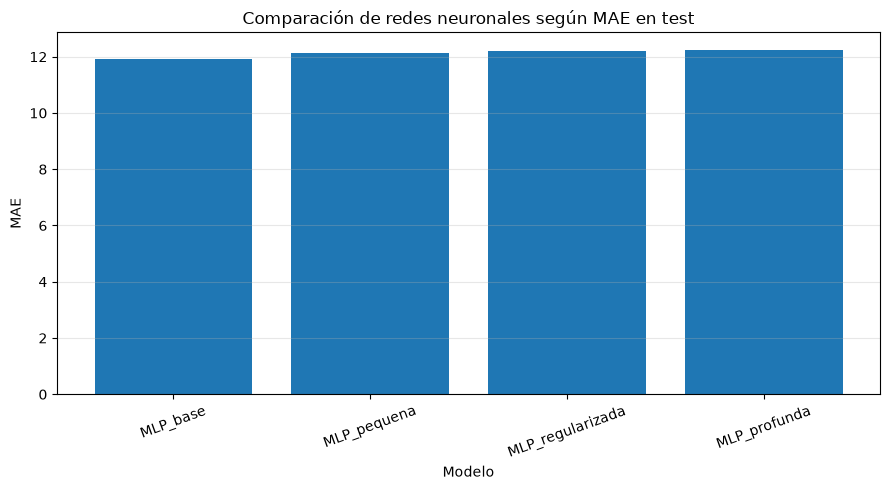

In [42]:
plt.figure(figsize=(9, 5))
plt.bar(resultados_mlp_df["modelo"], resultados_mlp_df["MAE_test"])
plt.title("Comparación de redes neuronales según MAE en test")
plt.xlabel("Modelo")
plt.ylabel("MAE")
plt.xticks(rotation=20)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

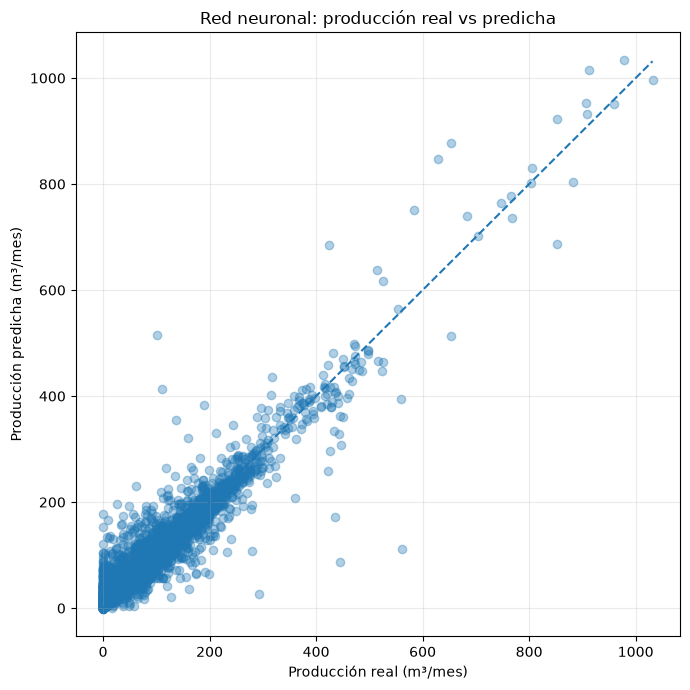

In [43]:
pred_nn_mejor = mejor_mlp.predict(X_test_nn_scaled)

plt.figure(figsize=(7, 7))
plt.scatter(y_test_nn, pred_nn_mejor, alpha=0.35)

plt.plot(
    [y_test_nn.min(), y_test_nn.max()],
    [y_test_nn.min(), y_test_nn.max()],
    linestyle="--"
)

plt.title("Red neuronal: producción real vs predicha")
plt.xlabel("Producción real (m³/mes)")
plt.ylabel("Producción predicha (m³/mes)")
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

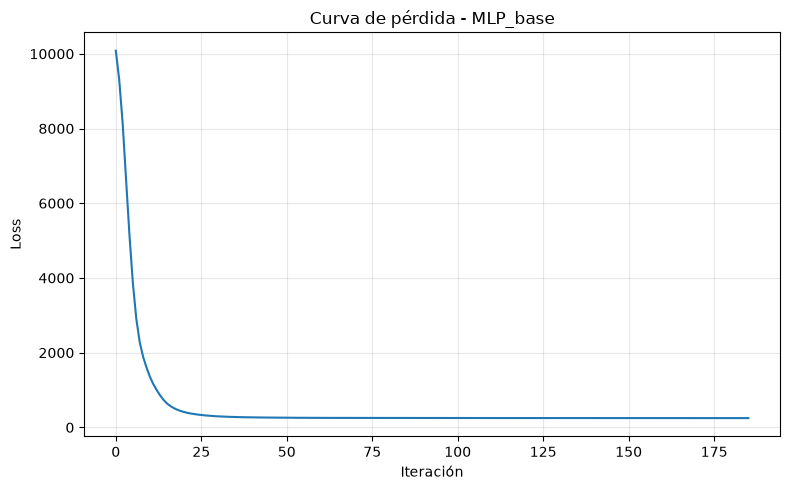

In [44]:
plt.figure(figsize=(8, 5))
plt.plot(mejor_mlp.loss_curve_)
plt.title(f"Curva de pérdida - {mejor_nombre}")
plt.xlabel("Iteración")
plt.ylabel("Loss")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

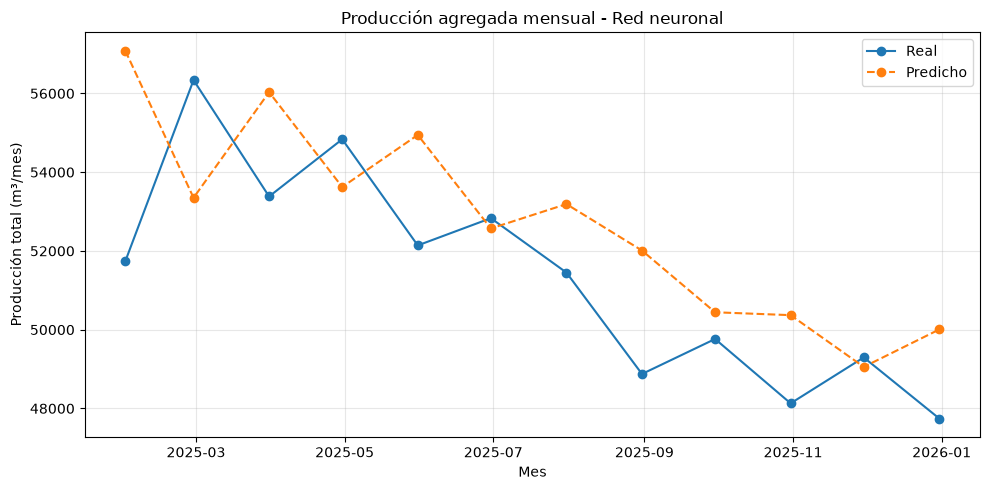

In [45]:
resultados_test_nn = test_nn[["idpozo", "fecha_data"]].copy()
resultados_test_nn["real"] = y_test_nn.values
resultados_test_nn["predicho"] = pred_nn_mejor

mensual_nn = (
    resultados_test_nn
    .groupby("fecha_data")[["real", "predicho"]]
    .sum()
    .sort_index()
)

plt.figure(figsize=(10, 5))
plt.plot(mensual_nn.index, mensual_nn["real"], marker="o", label="Real")
plt.plot(
    mensual_nn.index,
    mensual_nn["predicho"],
    marker="o",
    linestyle="--",
    label="Predicho"
)

plt.title("Producción agregada mensual - Red neuronal")
plt.xlabel("Mes")
plt.ylabel("Producción total (m³/mes)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## Conclusiones de la red neuronal

Se evaluaron distintas arquitecturas de redes neuronales multicapa para predecir la producción de petróleo a horizonte H1 utilizando el mismo esquema temporal y las mismas variables del modelo supervisado.

La mejor configuración fue `MLP_base`, que alcanzó un MAE de aproximadamente `11.91`, un RMSE de `24.48` y un R² de `0.912` sobre el conjunto de prueba de 2025.

La comparación entre entrenamiento y prueba no evidencia un sobreajuste marcado, ya que el MAE pasó de aproximadamente `11.53` en train a `11.91` en test.

Los gráficos de valores reales frente a predichos y de producción agregada mensual muestran que la red reproduce adecuadamente la tendencia general de producción, aunque persisten errores en algunos valores extremos y meses específicos.

A pesar de su buen desempeño, la red neuronal no supera a la Regresión Lineal seleccionada previamente, que mantiene un MAE ligeramente menor para el horizonte H1.

Por este motivo, la red neuronal se considera una alternativa complementaria y competitiva, mientras que la Regresión Lineal continúa siendo el modelo principal del proyecto.

In [46]:
comparacion_modelos = pd.DataFrame({
    "Modelo": [
        "Regresión Lineal",
        "Red Neuronal MLP"
    ],
    "MAE": [
        11.71,
        mean_absolute_error(y_test_nn, pred_nn_mejor)
    ],
    "RMSE": [
        24.24,
        mean_squared_error(y_test_nn, pred_nn_mejor) ** 0.5
    ],
    "R2": [
        0.914,
        r2_score(y_test_nn, pred_nn_mejor)
    ]
})

comparacion_modelos.round(3)

,Modelo,MAE,RMSE,R2
0,Regresión Lineal,11.710,24.240,0.914
1,Red Neuronal MLP,11.907,24.481,0.912


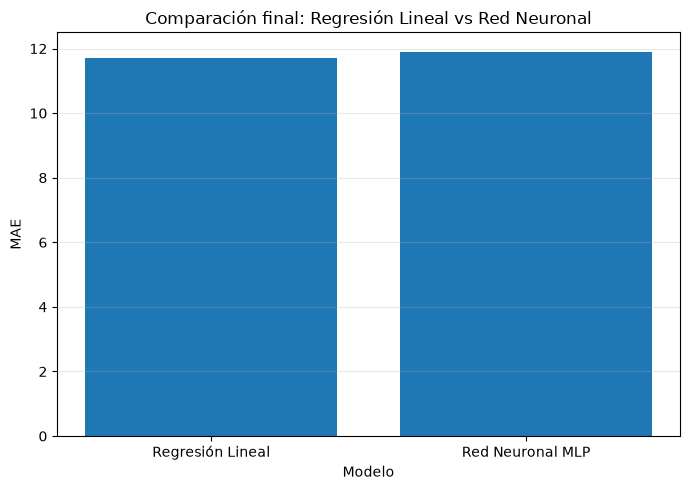

In [47]:
plt.figure(figsize=(7, 5))

plt.bar(
    comparacion_modelos["Modelo"],
    comparacion_modelos["MAE"]
)

plt.title("Comparación final: Regresión Lineal vs Red Neuronal")
plt.ylabel("MAE")
plt.xlabel("Modelo")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

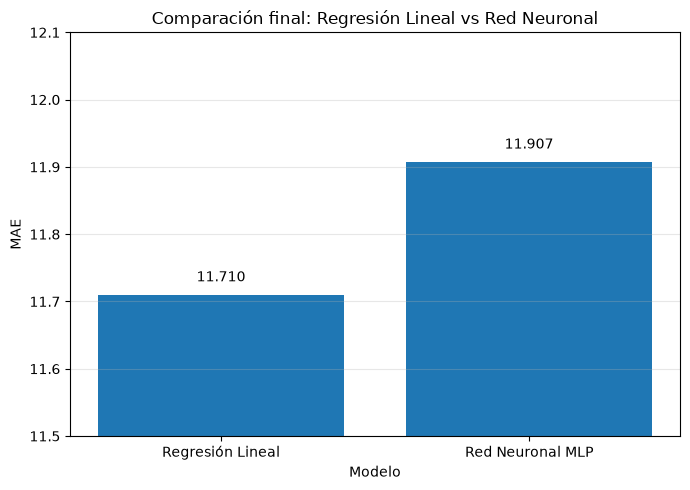

In [48]:
plt.figure(figsize=(7, 5))

plt.bar(
    comparacion_modelos["Modelo"],
    comparacion_modelos["MAE"]
)

plt.title("Comparación final: Regresión Lineal vs Red Neuronal")
plt.ylabel("MAE")
plt.xlabel("Modelo")

plt.ylim(11.5, 12.1)

for i, valor in enumerate(comparacion_modelos["MAE"]):
    plt.text(
        i,
        valor + 0.02,
        f"{valor:.3f}",
        ha="center"
    )

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

## Comparación final

La Regresión Lineal y la Red Neuronal MLP presentaron desempeños muy similares sobre el conjunto de prueba de 2025.

La Regresión Lineal obtuvo un MAE de `11.710`, mientras que la Red Neuronal alcanzó un MAE de `11.907`. La diferencia es pequeña, pero el modelo lineal conserva el menor error.

Además, la Regresión Lineal presenta una estructura más simple e interpretable, por lo que se mantiene como modelo predictivo principal del proyecto.

La Red Neuronal se incorpora como una alternativa complementaria y competitiva, demostrando que una arquitectura más compleja puede alcanzar resultados comparables, aunque en este caso no logra superar al modelo lineal.